Total Dataset: 960 | Train: 864 | Test: 96 | Kelas: 4
Epoch 1/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 11s 181ms/step - accuracy: 0.2442 - loss: 1.3967 - val_accuracy: 0.2604 - val_loss: 1.3802 - learning_rate: 0.0010
Epoch 2/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 150ms/step - accuracy: 0.3264 - loss: 1.3636 - val_accuracy: 0.4062 - val_loss: 1.2590 - learning_rate: 0.0010
Epoch 3/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 10s 143ms/step - accuracy: 0.4213 - loss: 1.2619 - val_accuracy: 0.4688 - val_loss: 1.1888 - learning_rate: 0.0010
Epoch 4/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 12s 164ms/step - accuracy: 0.4861 - loss: 1.1644 - val_accuracy: 0.4792 - val_loss: 1.1721 - learning_rate: 0.0010
Epoch 5/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 9s 172ms/step - accuracy: 0.5301 - loss: 1.0860 - val_accuracy: 0.5625 - val_loss: 1.1122 - learning_rate: 0.0010
Epoch 6/40
54/54 ━━━━━━━━━━━━━━━━━━━━ 8s 142ms/step - accuracy: 0.5694 - loss: 1.0148 - val_accuracy: 0.6146 - val_loss: 1.0228 - learning_rate: 0.0010
Epoch 7/40
54/54 ━━━━━━━━━━━━━━

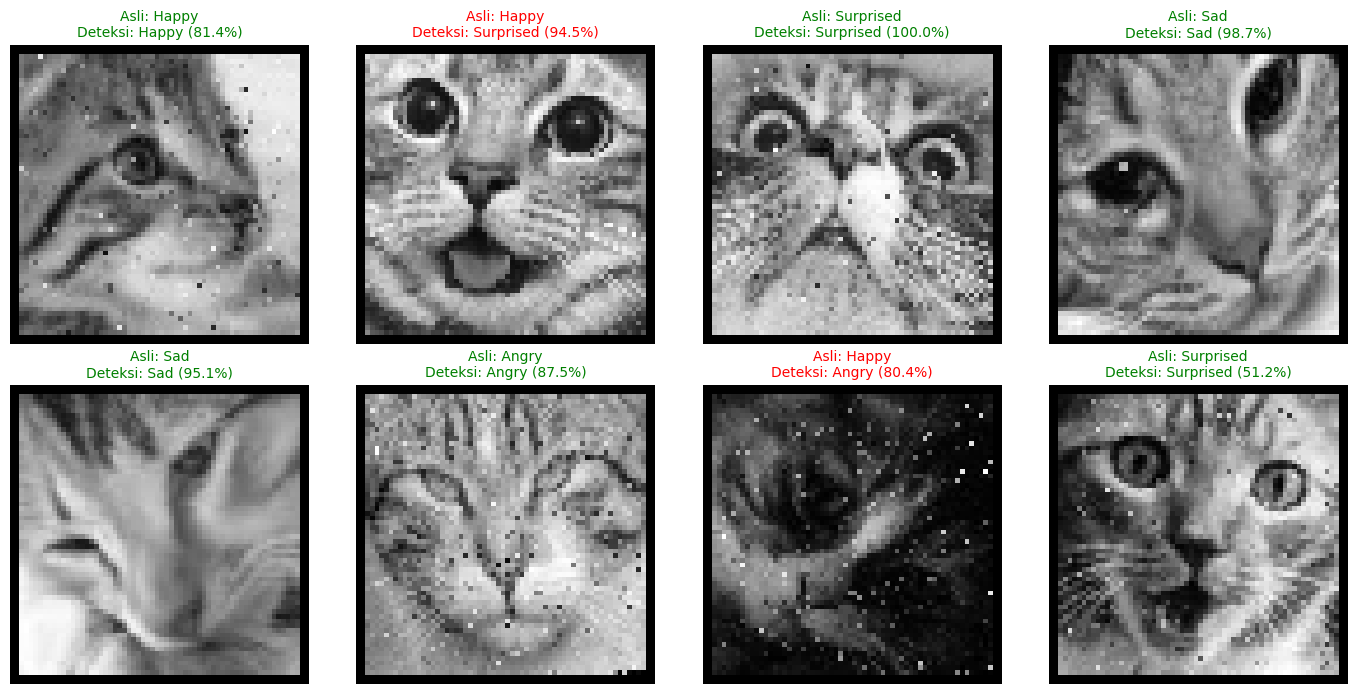


BERES! Download 'hasil_colab_fpga_lengkap.zip' dari panel kiri Colab.


In [7]:
import os, glob, cv2, shutil, yaml
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

tf.random.set_seed(42)
np.random.seed(42)

if not os.path.exists("cat-expression-cnn-soc"):
    !git clone https://github.com/rainyrein/cat-expression-cnn-soc.git

repo_dir = "cat-expression-cnn-soc/dataset"

shutil.rmtree("output_fpga", ignore_errors=True)
os.makedirs("output_fpga/dataset_64x64_bmp/train", exist_ok=True)
os.makedirs("output_fpga/dataset_64x64_bmp/test", exist_ok=True)
os.makedirs("output_fpga/verilog", exist_ok=True)
os.makedirs("output_fpga/laporan", exist_ok=True)

X_all, y_all = [], []

# 1. Preprocessing & Auto-Crop Wajah
for split in ["train", "valid", "test"]:
    for img_path in glob.glob(f"{repo_dir}/{split}/images/*.jpg"):
        lbl_path = img_path.replace("/images/", "/labels/").replace(".jpg", ".txt")
        if not os.path.exists(lbl_path):
            continue

        with open(lbl_path) as f:
            line = f.readline().strip()
            if not line:
                continue
            parts = line.split()
            class_id = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:5])

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is None:
            continue
        h, w = img.shape

        x1 = max(0, int((xc - bw / 2) * w))
        y1 = max(0, int((yc - bh / 2) * h))
        x2 = min(w, int((xc + bw / 2) * w))
        y2 = min(h, int((yc + bh / 2) * h))

        face_crop = img[y1:y2, x1:x2]
        if face_crop.size == 0:
            face_crop = img

        img_60 = cv2.resize(face_crop, (60, 60))
        img_64 = np.pad(img_60, pad_width=2, mode='constant', constant_values=0)

        X_all.append(img_64)
        y_all.append(class_id)

X_all = np.array(X_all, dtype=np.float32).reshape(-1, 64, 64, 1) / 255.0
y_all = np.array(y_all)
num_classes = len(np.unique(y_all))

# Split 90% Train (864) : 10% Test (96)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.10, random_state=42, stratify=y_all
)

for idx in range(10):
    cv2.imwrite(f"output_fpga/dataset_64x64_bmp/train/cat_train_{idx}_cls{y_train[idx]}.bmp", (X_train[idx].reshape(64, 64)*255).astype(np.uint8))
    cv2.imwrite(f"output_fpga/dataset_64x64_bmp/test/cat_test_{idx}_cls{y_test[idx]}.bmp", (X_test[idx].reshape(64, 64)*255).astype(np.uint8))

sample_img_64 = (X_test[0].reshape(64, 64) * 255).astype(np.uint8)
print(f"Total Dataset: {len(X_all)} | Train: {len(X_train)} | Test: {len(X_test)} | Kelas: {num_classes}")

# 2. Arsitektur 3-Blok CNN + Flatten (Terbukti cepat naik sejak Epoch 2)
model = models.Sequential([
    layers.Input(shape=(64, 64, 1)),
    layers.RandomFlip("horizontal"),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_cat_model.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=0
)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0
)

model.fit(
    X_train, y_train,
    epochs=40,
    batch_size=16,
    validation_data=(X_test, y_test),
    callbacks=[checkpoint, lr_scheduler]
)

# 3. Evaluasi Model Terbaik
best_model = tf.keras.models.load_model("best_cat_model.keras")

loss_train, acc_train = best_model.evaluate(X_train, y_train, verbose=0)
loss_test, acc_test = best_model.evaluate(X_test, y_test, verbose=0)

print("\n==========================================")
print(f"AKURASI TRAINING TERBAIK : {acc_train * 100:.2f}%")
print(f"AKURASI TESTING TERBAIK  : {acc_test * 100:.2f}%")
print("==========================================\n")

with open(f"{repo_dir}/data.yaml", "r") as f:
    class_names = yaml.safe_load(f)['names']

y_pred_probs = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("Rincian Deteksi Per Ekspresi Wajah Kucing:")
print(classification_report(y_test, y_pred, target_names=class_names))

plt.figure(figsize=(14, 7))
for i in range(min(8, len(X_test))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_test[i].reshape(64, 64), cmap='gray')
    asli = class_names[y_test[i]]
    tebakan = class_names[y_pred[i]]
    conf = y_pred_probs[i][y_pred[i]] * 100
    warna = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(f"Asli: {asli}\nDeteksi: {tebakan} ({conf:.1f}%)", color=warna, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.savefig("output_fpga/laporan/hasil_deteksi_ekspresi.png", bbox_inches='tight')
plt.show()

# 4. Export Bobot Conv2D Pertama & Sampel Citra ke .hex untuk Verilogjhnn
conv_layer = [l for l in best_model.layers if isinstance(l, layers.Conv2D)][0]
weights = conv_layer.get_weights()[0]
weights_int8 = np.clip(np.round(weights * 64), -128, 127).astype(np.int8)

with open("output_fpga/verilog/cnn_weights.hex", "w") as f:
    for w in weights_int8.flatten():
        f.write(f"{(int(w) & 0xFF):02x}\n")

with open("output_fpga/verilog/cat_sample_image.hex", "w") as f:
    for p in sample_img_64.flatten():
        f.write(f"{p:02x}\n")

shutil.make_archive("hasil_colab_fpga_lengkap", 'zip', "output_fpga")
print("\nBERES! Download 'hasil_colab_fpga_lengkap.zip' dari panel kiri Colab.")